In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**LOADING THE DATA**

In [2]:
dataset = pd.read_csv("titanic.csv")

In [3]:
dataset.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S


In [4]:
dataset.shape

(891, 12)

In [5]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
dataset.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
dataset["Survived"].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

**FIND PATTERNS WITH BAR CHART**

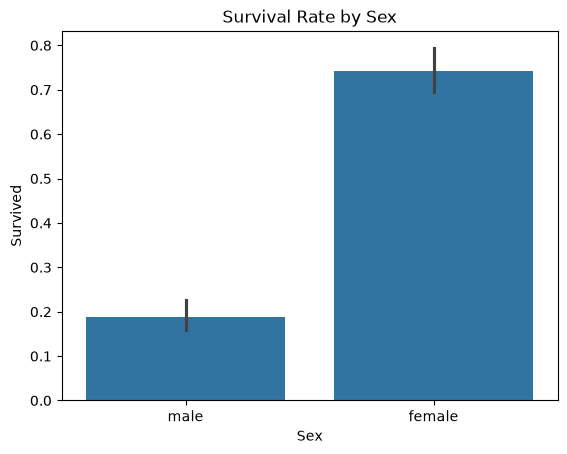

In [8]:
#Bar Charts for survival rate by Sex
sns.barplot(x="Sex",y="Survived",data=dataset)
plt.title("Survival Rate by Sex")
plt.show()

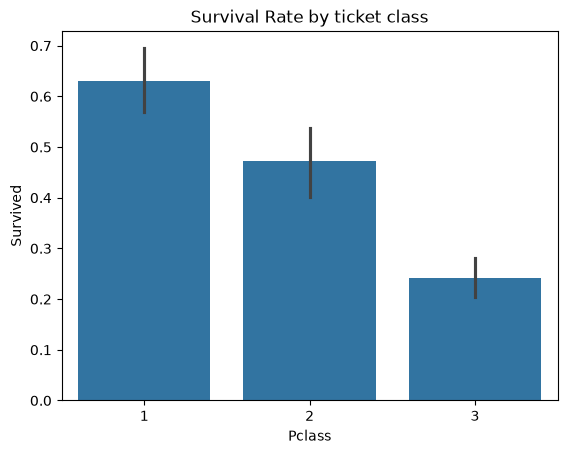

In [9]:
#Bar Charts for survival rate by Sex
sns.barplot(x="Pclass",y="Survived",data=dataset)
plt.title("Survival Rate by ticket class")
plt.show()

Women survived about four times as often as men, and survival fell with each step down in class.  About 74% of women survived versus 19% of men, so Sex looks like the strongest predictor.The thin black line on each bar is a confidence interval.

**FILLING IN MISSING VALUES**

In [10]:
from sklearn.impute import SimpleImputer

In [11]:
si_age = SimpleImputer(strategy="median")
dataset[["Age"]]= si_age.fit_transform(dataset[["Age"]])

In [12]:
si_embarked = SimpleImputer(strategy="most_frequent")
dataset[["Embarked"]] = si_embarked.fit_transform(dataset[["Embarked"]])

In [13]:
dataset.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

PassengerId and Name are unique to each person, so no pattern can be learned from them. Ticket is messy codes. Cabin is 77% empty, so filling it would mean inventing most of it so delete these columns.

In [14]:
dataset.drop(columns=["PassengerId","Name","Ticket","Cabin"],inplace=True)

In [15]:
# Choosing features and target
x = dataset.iloc[:,1:]
y = dataset["Survived"]

In [16]:
print(x.columns.tolist())
print(x.shape)
print(x.isnull().sum().sum())

['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
(891, 7)
0


In [17]:
dataset

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S
...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S
887,1,1,female,19.0,0,0,30.0000,S
888,0,3,female,28.0,1,2,23.4500,S
889,1,1,male,26.0,0,0,30.0000,C


**ENCODING USING ONE_HOT ENCODER**

In [18]:
from sklearn.preprocessing import OneHotEncoder

In [19]:
from sklearn.preprocessing import OneHotEncoder

cat_cols = ["Sex", "Embarked"]

enc = OneHotEncoder()
encoded = pd.DataFrame(
    enc.fit_transform(x[cat_cols]).toarray(),
    columns=enc.get_feature_names_out(cat_cols),
    index=x.index,
)

x = pd.concat([x.drop(columns=cat_cols), encoded], axis=1)
x.head(3)

,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,3,22.0,1,0,7.2500,0.0,1.0,0.0,0.0,1.0
1,1,38.0,1,0,71.2833,1.0,0.0,1.0,0.0,0.0
2,3,26.0,0,0,7.9250,1.0,0.0,0.0,0.0,1.0


**SPLIT INTO TRAIN AND TEST**

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [22]:
print(x_train.shape, x_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(712, 10) (179, 10)
0.383 0.385


**FEATURE SCALING**

In [23]:
from sklearn.preprocessing import StandardScaler

In [24]:
num_cols = ["Age", "Fare", "SibSp", "Parch", "Pclass"]

In [39]:
sc = StandardScaler()
x_train[num_cols] = sc.fit_transform(x_train[num_cols])
x_test[num_cols] = sc.transform(x_test[num_cols])

print(x_train[num_cols].describe().loc[["mean", "std"]].round(2))
x_train.head(3).round(2)

      Age  Fare  SibSp  Parch  Pclass
mean  0.0  -0.0    0.0    0.0     0.0
std   1.0   1.0    1.0    1.0     1.0


,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
692,0.83,-0.11,-0.47,-0.47,0.51,0.0,1.0,0.0,0.0,1.0
481,-0.37,-0.11,-0.47,-0.47,-0.66,0.0,1.0,0.0,0.0,1.0
527,-1.57,-0.11,-0.47,-0.47,3.96,0.0,1.0,0.0,0.0,1.0


**TRAINING MODEL**

In [40]:
from sklearn.linear_model import LogisticRegression

In [41]:
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train,y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [42]:
print("Training Accuracy:",lr.score(x_train,y_train)*100)

Training Accuracy: 80.75842696629213


In [43]:
print("Test score:",lr.score(x_test,y_test)*100)

Test score: 79.88826815642457


**EVALUATE ON THE TEST SET**

In [44]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score, confusion_matrix

In [45]:
predict = lr.predict(x_test)

In [46]:
accuracy_score(y_test,predict)*100

79.88826815642457

In [47]:
precision_score(y_test,predict)*100

77.96610169491525

In [48]:
recall_score(y_test,predict)*100

66.66666666666666

In [49]:
f1_score(y_test,predict)*100

71.875

In [50]:
cm = confusion_matrix(y_test,predict)

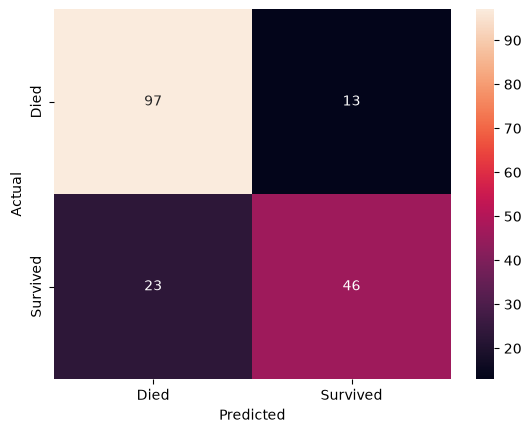

In [51]:
sns.heatmap(cm,annot=True,fmt="d",
            xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

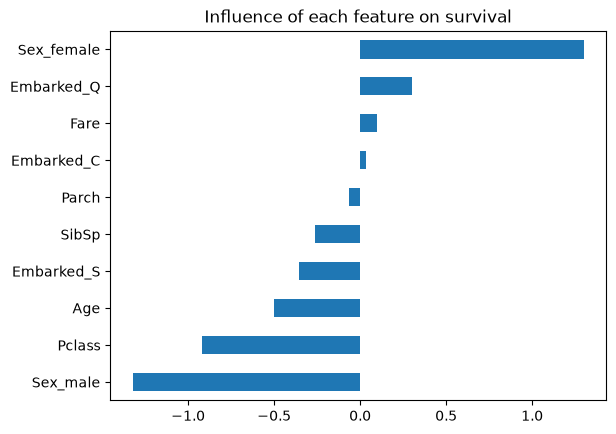

In [52]:
coefs = pd.Series(lr.coef_[0], index=x_train.columns).sort_values()
coefs.plot(kind="barh")
plt.title("Influence of each feature on survival")
plt.show()


I built a Logistic Regression classifier to predict Titanic survival from
class, sex, age, family size, fare and port of embarkation. Missing ages were
filled with the median and text columns were one-hot encoded. The model
reached 80.4% accuracy on unseen passengers, close to its 80.8% training score,
so it did not overfit. Sex was the strongest predictor, followed by ticket class
and age, which matches the "women and children first" evacuation. A limitation
is that recall for survivors is only 0.67, so the model misses about one in
three people who survived; the dataset is also small, and 20% of ages were estimated.